In [1]:
# Step I : Import libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1, 28, 28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

In [3]:
# Step III : Preprocessing
x_train = x_train.reshape(-1,784).astype('float32') / 255.0
x_test = x_test.reshape(-1,784).astype('float32') / 255.0

In [4]:
y_train = tf.keras.utils.to_categorical(y_train,10)
y_test = tf.keras.utils.to_categorical(y_test,10)

In [5]:
# Step IV : Model Configuration
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(64,activation='relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])

In [6]:
# Step V : Model Compilation
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
# Step VI : Training Phase
history = model.fit(x_train,y_train,
                    epochs=5,batch_size=64)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9218 - loss: 0.2685
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9664 - loss: 0.1130
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9765 - loss: 0.0778
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9822 - loss: 0.0592
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9855 - loss: 0.0466


In [8]:

# Step VIII : Tune Activation Function
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(64,activation='tanh'),
    tf.keras.layers.Dense(32,activation='tanh'),
    tf.keras.layers.Dense(10,activation='softmax')
])

In [9]:
model2.compile(optimizer='adam',
               loss='categorical_crossentropy',
               metrics=['accuracy'])

model2.fit(x_train,y_train,epochs=5,batch_size=64)

loss2,accuracy2 = model2.evaluate(x_test,y_test)
print("Tuned Accuracy:",accuracy2)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9035 - loss: 0.3570
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9514 - loss: 0.1663
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9650 - loss: 0.1183
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9733 - loss: 0.0913
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9777 - loss: 0.0734
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9716 - loss: 0.0972
Tuned Accuracy: 0.9715999960899353


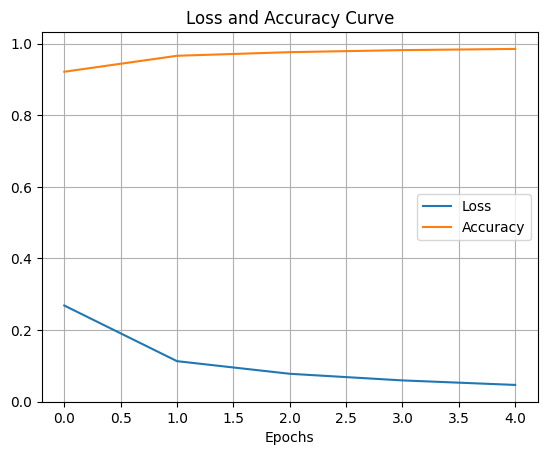

In [10]:

# Step IX : Plot Loss and Accuracy Curves
plt.plot(history.history['loss'],label='Loss')
plt.plot(history.history['accuracy'],label='Accuracy')
plt.xlabel("Epochs")
plt.title("Loss and Accuracy Curve")
plt.legend()
plt.grid()
plt.show()
